### DATASET LINK: https://www.kaggle.com/datasets/ruchi798/bookcrossing-dataset

In [1]:
import os 

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/ruchi798/bookcrossing-dataset/Book reviews/Book reviews/BX-Book-Ratings.csv
/kaggle/input/datasets/ruchi798/bookcrossing-dataset/Book reviews/Book reviews/BX-Users.csv
/kaggle/input/datasets/ruchi798/bookcrossing-dataset/Book reviews/Book reviews/BX_Books.csv
/kaggle/input/datasets/ruchi798/bookcrossing-dataset/Books Data with Category Language and Summary/Preprocessed_data.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Books

In [11]:
books = pd.read_csv("/kaggle/input/datasets/ruchi798/bookcrossing-dataset/Book reviews/Book reviews/BX_Books.csv", sep=";", encoding="latin-1")
books.columns

Index(['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher',
       'Image-URL-S', 'Image-URL-M', 'Image-URL-L'],
      dtype='object')

In [12]:
books.columns = ['ISBN', 'bookTitle', 'bookAuthor', 'yearOfPublication', 'publisher', 'imageUrlS', 'imageUrlM', 'imageUrlL']
books.columns

Index(['ISBN', 'bookTitle', 'bookAuthor', 'yearOfPublication', 'publisher',
       'imageUrlS', 'imageUrlM', 'imageUrlL'],
      dtype='object')

In [32]:
print(books.shape)

(271379, 8)


In [33]:
books.head()

,ISBN,bookTitle,bookAuthor,yearOfPublication,publisher,imageUrlS,imageUrlM,imageUrlL
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


### Users

In [24]:
users = pd.read_csv("/kaggle/input/datasets/ruchi798/bookcrossing-dataset/Book reviews/Book reviews/BX-Users.csv", sep=";", encoding="latin-1")
users.columns

Index(['User-ID', 'Location', 'Age'], dtype='object')

In [25]:
users.columns = ["userID", "Location", "Age"]
users.columns

Index(['userID', 'Location', 'Age'], dtype='object')

In [31]:
print(users.shape)

(278858, 3)


In [34]:
users.head()

,userID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


### Ratings

In [26]:
ratings = pd.read_csv("/kaggle/input/datasets/ruchi798/bookcrossing-dataset/Book reviews/Book reviews/BX-Book-Ratings.csv", sep=";", encoding="latin-1")
ratings.columns

Index(['User-ID', 'ISBN', 'Book-Rating'], dtype='object')

In [27]:
ratings.columns = ["userID", "ISBN", "bookRating"]
ratings.columns

Index(['userID', 'ISBN', 'bookRating'], dtype='object')

In [29]:
print(ratings.shape),
print(list(ratings.columns))

(1149780, 3)
['userID', 'ISBN', 'bookRating']


In [35]:
ratings.head()

,userID,ISBN,bookRating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


#### Plotting

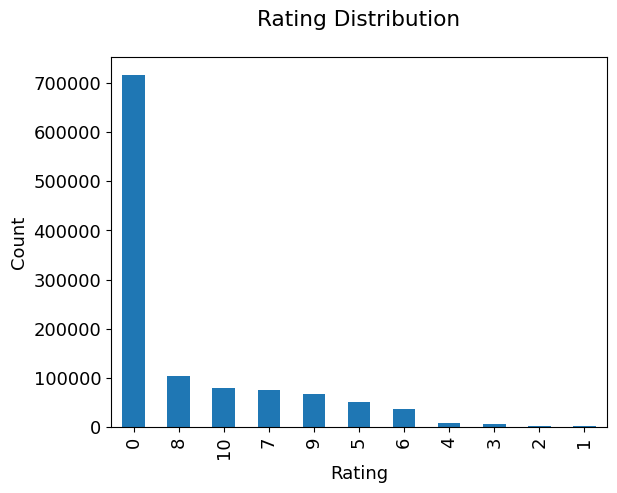

In [37]:
plt.rc("font", size=13)
ratings.bookRating.value_counts(sort=True).plot(kind="bar")
plt.title("Rating Distribution\n")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

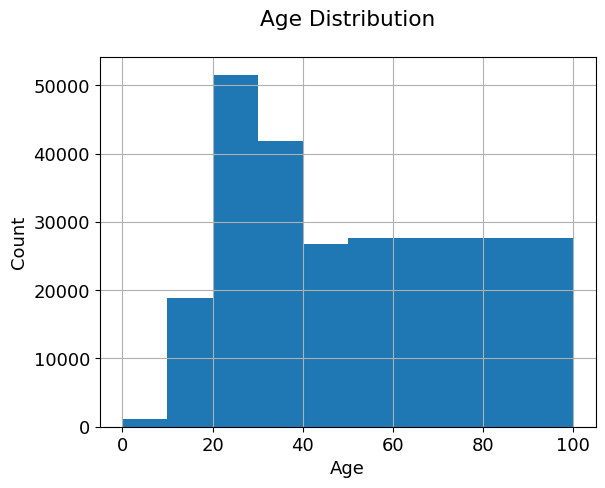

In [39]:
users.Age.hist(bins=[0,10,20,30,40,50,100])
plt.title("Age Distribution\n")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

To ensure statistical significance, users with less than 200 ratings, and books with less than 100 ratings are excluded.

In [51]:
counts1 = ratings['userID'].value_counts()
ratings = ratings[ratings['userID'].isin(counts1[counts1 >= 200].index)]

In [52]:
counts = ratings['bookRating'].value_counts()
ratings = ratings[ratings['bookRating'].isin(counts[counts >= 100].index)]

### Collaborative Filtering Using k-Nearest Neighbors (kNN)

- kNN is a ml algo to find clusters of similar users based on common ratings, and make predictions using the average rating of top-k nearest neighbors.

- For example, we first present ratings in a matrix with the having one row for each item(book) and one column for each user.

In [56]:
ratings.columns, books.columns

(Index(['userID', 'ISBN', 'bookRating'], dtype='object'),
 Index(['ISBN', 'bookTitle', 'bookAuthor', 'yearOfPublication', 'publisher',
        'imageUrlS', 'imageUrlM', 'imageUrlL'],
       dtype='object'))

In [57]:
combine_book_rating = pd.merge(ratings, books, on="ISBN")

In [58]:
combine_book_rating.head()

,userID,ISBN,bookRating,bookTitle,bookAuthor,yearOfPublication,publisher,imageUrlS,imageUrlM,imageUrlL
0,277427,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley & Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...
1,277427,0026217457,0,Vegetarian Times Complete Cookbook,Lucy Moll,1995,John Wiley & Sons,http://images.amazon.com/images/P/0026217457.0...,http://images.amazon.com/images/P/0026217457.0...,http://images.amazon.com/images/P/0026217457.0...
2,277427,003008685X,8,Pioneers,James Fenimore Cooper,1974,Thomson Learning,http://images.amazon.com/images/P/003008685X.0...,http://images.amazon.com/images/P/003008685X.0...,http://images.amazon.com/images/P/003008685X.0...
3,277427,0030615321,0,"Ask for May, Settle for June (A Doonesbury book)",G. B. Trudeau,1982,Henry Holt & Co,http://images.amazon.com/images/P/0030615321.0...,http://images.amazon.com/images/P/0030615321.0...,http://images.amazon.com/images/P/0030615321.0...
4,277427,0060002050,0,On a Wicked Dawn (Cynster Novels),Stephanie Laurens,2002,Avon Books,http://images.amazon.com/images/P/0060002050.0...,http://images.amazon.com/images/P/0060002050.0...,http://images.amazon.com/images/P/0060002050.0...


In [59]:
columns = ['yearOfPublication', 'publisher', 'bookAuthor', 'imageUrlS', 'imageUrlM', 'imageUrlL']

In [60]:
combine_book_rating = combine_book_rating.drop(columns, axis=1)
combine_book_rating.head()

,userID,ISBN,bookRating,bookTitle
0,277427,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...
1,277427,0026217457,0,Vegetarian Times Complete Cookbook
2,277427,003008685X,8,Pioneers
3,277427,0030615321,0,"Ask for May, Settle for June (A Doonesbury book)"
4,277427,0060002050,0,On a Wicked Dawn (Cynster Novels)


#### Now we will group by book titles and create a new column for total rating count.

In [62]:
combine_book_rating = combine_book_rating.dropna(axis=0, subset=['bookTitle'])

book_ratingCount = (
    combine_book_rating
    .groupby(by=['bookTitle'])['bookRating']
    .count()
    .reset_index()
    .rename(columns={'bookRating': 'totalRatingCount'})
    [['bookTitle', 'totalRatingCount']]
)

book_ratingCount.head()

,bookTitle,totalRatingCount
0,A Light in the Storm: The Civil War Diary of ...,2
1,Always Have Popsicles,1
2,Apple Magic (The Collector's series),1
3,Beyond IBM: Leadership Marketing and Finance ...,1
4,Clifford Visita El Hospital (Clifford El Gran...,1


#### Now we will combine the rating data with the total rating count data, this gives us exactly what we need to find out which books are popular and filter out lesser-known books.

In [64]:
rating_with_totalRatingCount = combine_book_rating.merge(
    book_ratingCount, left_on='bookTitle', right_on='bookTitle', how='left'
)
rating_with_totalRatingCount.head()

,userID,ISBN,bookRating,bookTitle,totalRatingCount
0,277427,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...,82
1,277427,0026217457,0,Vegetarian Times Complete Cookbook,7
2,277427,003008685X,8,Pioneers,1
3,277427,0030615321,0,"Ask for May, Settle for June (A Doonesbury book)",1
4,277427,0060002050,0,On a Wicked Dawn (Cynster Novels),13


In [66]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)
book_ratingCount['totalRatingCount'].describe()

count   160587.000
mean         3.044
std          7.428
min          1.000
25%          1.000
50%          1.000
75%          2.000
max        365.000
Name: totalRatingCount, dtype: float64

In [67]:
book_ratingCount['totalRatingCount'].quantile(np.arange(.9,1,.01))

0.900    5.000
0.910    6.000
0.920    7.000
0.930    7.000
0.940    8.000
0.950   10.000
0.960   11.000
0.970   14.000
0.980   19.000
0.990   31.000
Name: totalRatingCount, dtype: float64

In [69]:
popularity_threshold = 50
rating_popular_book = rating_with_totalRatingCount.query('totalRatingCount >= @popularity_threshold')

rating_popular_book.head()

,userID,ISBN,bookRating,bookTitle,totalRatingCount
0,277427,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...,82
13,277427,0060930535,0,The Poisonwood Bible: A Novel,133
15,277427,0060934417,0,Bel Canto: A Novel,108
18,277427,0061009059,9,One for the Money (Stephanie Plum Novels (Pape...,108
24,277427,006440188X,0,The Secret Garden,79


### Filter to users in US and Canada only

In [73]:
combined = rating_popular_book.merge(users, left_on='userID', right_on='userID', how='left')

us_canada_user_rating = combined[combined['Location'].str.contains('usa|canada')]

us_canada_user_rating = us_canada_user_rating.drop('Age', axis=1)

us_canada_user_rating.head()

,userID,ISBN,bookRating,bookTitle,totalRatingCount,Location
0,277427,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...,82,"gilbert, arizona, usa"
1,277427,0060930535,0,The Poisonwood Bible: A Novel,133,"gilbert, arizona, usa"
2,277427,0060934417,0,Bel Canto: A Novel,108,"gilbert, arizona, usa"
3,277427,0061009059,9,One for the Money (Stephanie Plum Novels (Pape...,108,"gilbert, arizona, usa"
4,277427,006440188X,0,The Secret Garden,79,"gilbert, arizona, usa"


## Implementing kNN

- We convert our table to a 2D matrix, and fill the missing values with zeros (since we will calculate distances between rating vectors).

- We then transform the values(ratings) of the matrix dataframe into a scipy sparse matrix for more efficient calculations.

In [74]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

In [76]:
us_canada_user_rating = us_canada_user_rating.drop_duplicates(['userID', 'bookTitle'])

us_canada_user_rating_pivot = us_canada_user_rating.pivot(
    index='bookTitle', columns='userID', values='bookRating').fillna(0)

us_canada_user_rating_matrix = csr_matrix(us_canada_user_rating_pivot.values)

In [79]:
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(us_canada_user_rating_matrix)

NearestNeighbors(algorithm='brute', metric='cosine')

In [93]:
query_index = np.random.choice(us_canada_user_rating_pivot.shape[0])
print("query_index: ", query_index)

print(
    us_canada_user_rating_pivot.iloc[query_index, :].values.reshape(1,-1)
)

distance, indices = model_knn.kneighbors(
    us_canada_user_rating_pivot.iloc[query_index, :].values.reshape(1, -1), n_neighbors=6
)

us_canada_user_rating_pivot.index[query_index]

query_index:  676
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 9. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 5. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 8. 0. 0. 0.
  0. 8. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 7. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 

'The Winner'

In [99]:
for i in range(0, len(distance.flatten())):
    if i == 0:
        print(
            'Recommendations for {0}: \n'.format(us_canada_user_rating_pivot.index[query_index])
        )
    else:
        print(
            '{0}: {1}, with distance of {2}: '.format(
                i, us_canada_user_rating_pivot.index[indices.flatten()[i]], distance.flatten()[i]
            )
        )

Recommendations for The Winner: 

1: The Alibi, with distance of 0.6885242154961377: 
2: The First Counsel, with distance of 0.6989263572616156: 
3: Echoes, with distance of 0.7125193595706858: 
4: Saving Faith, with distance of 0.7186335198079701: 
5: Winter Solstice, with distance of 0.7852038835295931: 
